   cell_id      ndvi      ndbi  impervious_pct  road_density_km_km2  \
0        0  0.325637 -0.207903       59.043725                  NaN   
1        1  0.217034 -0.159759       74.126761            24.844960   
2        2  0.160051 -0.127417       76.528328            37.069438   
3        3  0.156749 -0.112085       77.903810            14.902990   
4        4  0.128992 -0.074170       79.078385            17.275134   

   major_road_density_km_km2  population_density_km2  nei_emissions_tpy  \
0                        NaN            94806.493276                NaN   
1                        NaN            90094.319191                NaN   
2                        NaN            33870.886499                NaN   
3                        NaN            37004.413783                NaN   
4                        NaN            60620.636728                NaN   

   nei_point_emissions_tpy nei_area_emissions_tpy  ...  \
0                      NaN                   None  ...   
1     

<Axes: >

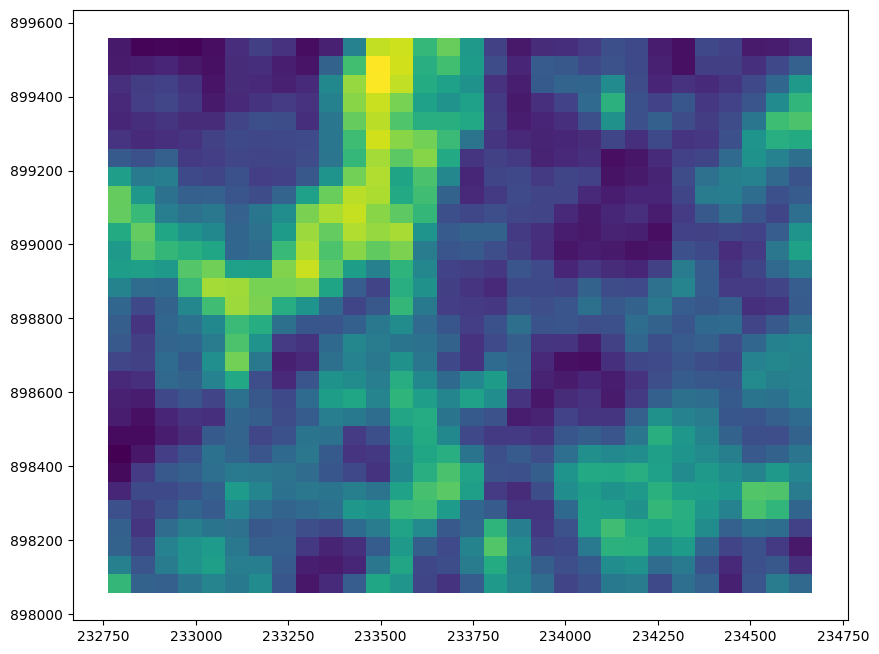

In [17]:
src_path = "/Users/legariapena.j/Documents/open-sensing-analysis/open-sensing-analysis/data/labelled_lattice.geojson"

import geopandas as gpd

gdf = gpd.read_file(src_path)
print(gdf.head())

#Let's visualizee different layers

import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(10, 10))
gdf.plot(ax=ax, cmap = "viridis", column = "ndvi")

In [18]:
gdf.columns

Index(['cell_id', 'ndvi', 'ndbi', 'impervious_pct', 'road_density_km_km2',
       'major_road_density_km_km2', 'population_density_km2',
       'nei_emissions_tpy', 'nei_point_emissions_tpy',
       'nei_area_emissions_tpy', 'gvi_mean', 'gvi_median', 'gvi_std',
       'facade_area_mean', 'facade_area_median', 'facade_area_std',
       'n_cars_mean', 'n_cars_median', 'n_cars_std', 'sky_ratio_mean',
       'sky_ratio_median', 'sky_ratio_std', 'road_ratio_mean',
       'road_ratio_median', 'road_ratio_std', 'temperature_sat_ridge',
       'temperature_sat_kriging_correction', 'temperature_sat',
       'pm25_sat_ridge', 'pm25_sat', 'temperature_sv_ridge',
       'temperature_sv_kriging_correction', 'temperature_sv', 'pm25_sv_ridge',
       'pm25_sv', 'geometry'],
      dtype='object')

15
15
0 ndvi
0 0
1 ndbi
0 1
2 impervious_pct
0 2
3 road_density_km_km2
0 3
4 major_road_density_km_km2
1 0
5 population_density_km2
1 1
6 gvi_mean
1 2
7 facade_area_mean
1 3
8 n_cars_mean
2 0
9 sky_ratio_mean
2 1
10 road_ratio_mean
2 2
11 temperature_sat
2 3
12 pm25_sat
3 0
13 temperature_sv
3 1
14 pm25_sv
3 2


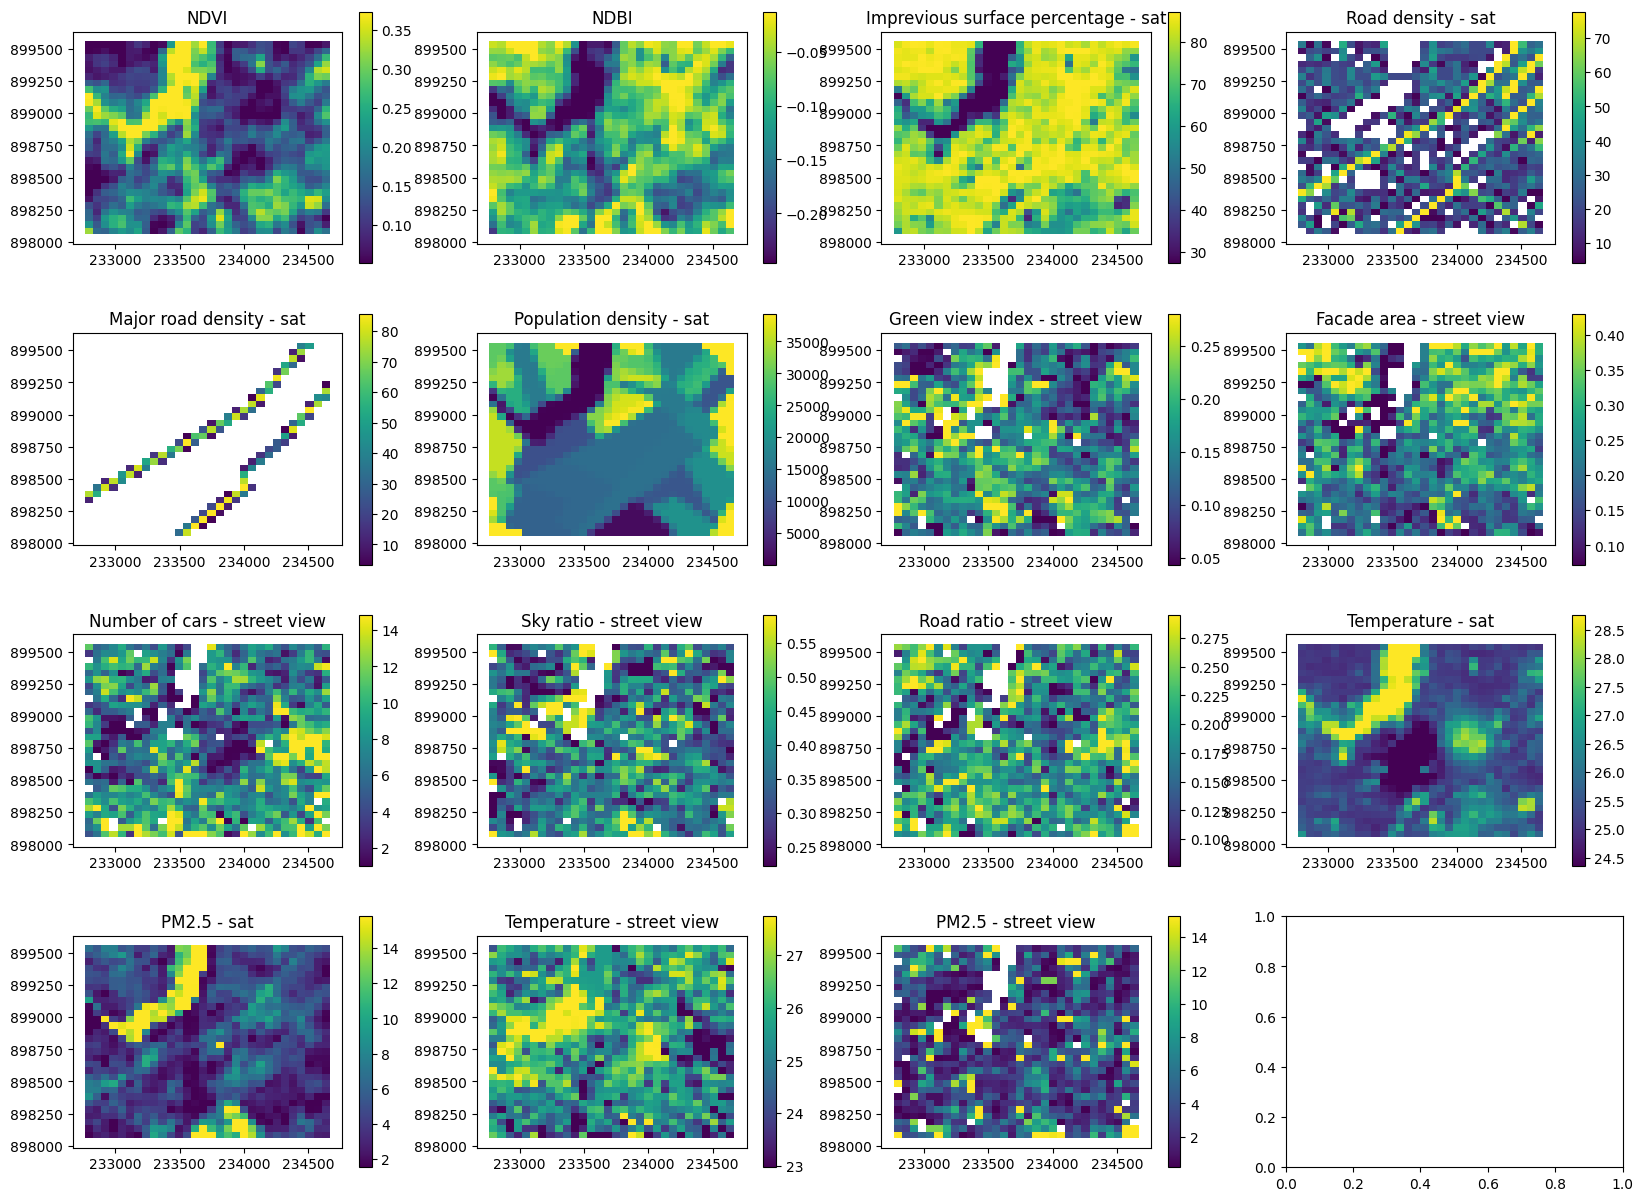

In [21]:
columns_to_add = ["ndvi", "ndbi", "impervious_pct", "road_density_km_km2", "major_road_density_km_km2", "population_density_km2",
                  "gvi_mean", "facade_area_mean", "n_cars_mean", "sky_ratio_mean", "road_ratio_mean", "temperature_sat", "pm25_sat", 'temperature_sv', "pm25_sv"]


titles = ["NDVI", "NDBI", "Imprevious surface percentage - sat", "Road density - sat", "Major road density - sat", "Population density - sat", "Green view index - street view", 
          "Facade area - street view", "Number of cars - street view", "Sky ratio - street view", "Road ratio - street view", "Temperature - sat", "PM2.5 - sat", "Temperature - street view", "PM2.5 - street view"]
number_of_maps = len(columns_to_add)
print(number_of_maps)
print(len(titles))
max_maps_per_row = 4
min_percentile = 5
max_percentile = 95

#Add clipped values to the gdf
for column in columns_to_add:
    min_value = gdf[column].quantile(min_percentile / 100)
    max_value = gdf[column].quantile(max_percentile / 100)
    gdf[column + "_clipped"] = gdf[column].clip(lower=min_value, upper=max_value)

fig, axes = plt.subplots(nrows=(number_of_maps // max_maps_per_row) + 1, ncols=max_maps_per_row, figsize=(20, 15))
for i, column in enumerate(columns_to_add):
    print(i, column)
    row = i // max_maps_per_row
    col = i % max_maps_per_row

    print(row, col)
    gdf.plot(ax=axes[row, col], column=column + "_clipped", cmap="viridis", legend=True)
    axes[row, col].set_title(titles[i])

In [20]:
gdf["temperature_sv_ridge"]

0      26.514629
1      25.794772
2      25.961562
3      24.900726
4      23.517808
         ...    
895    24.599217
896    22.896220
897    27.435538
898    26.451268
899    24.554042
Name: temperature_sv_ridge, Length: 900, dtype: float64